# CartPole in closed loop

The recurrent spiking network (50 LIF + 50 ALIF neurons) controls CartPole. 
At each decision step the observation is encoded as Poisson spike trains (ON/OFF channels of the 4 observation values) together with a $10 Hz$ Poisson background, and held for 5 ms of network time (5 steps with $dt = 1 ms$).
The action is sampled from the softmax of two policy readouts at the end of these $5 ms$, and a third readout estimates the value.

In [1]:
import time
from pathlib import Path

import gymnax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from snnrl import network
from snnrl.network import init_weights, make_network_params
from snnrl.neuron import make_params
from snnrl.rl import discounted_returns, rollout, rollout_batch, split_readout, train_actor_critic
from snnrl.inputs import ObservationEncoder
from snnrl.utils import save_results, load_results

In [2]:
N_LIF = 50
N_ALIF = 50
N_OUT = 3  # two policy readouts and the value
GAMMA = 0.99
N_ITER = 600 # number of training iterations
RATE_MAX = 200.0 # (Hz) rate of a channel at maximum value

RETRAIN = False
SEED = 0

main_key = jax.random.key(SEED)

init_key, train_key, test_key, analysis_key = jax.random.split(main_key, 4)

PATH_BPTT = Path("results/06_cartpole_bptt.npz")
PATH_EPROP = Path("results/06_cartpole_eprop.npz")

In [3]:
env, env_params = gymnax.make("CartPole-v1")
encoder = ObservationEncoder(rate_max=RATE_MAX)

params = {
    "BPTT": make_network_params(make_params(n_lif=N_LIF, n_alif=N_ALIF)),
    "e-prop": make_network_params(make_params(n_lif=N_LIF, n_alif=N_ALIF, stop_z_gradient=True)),
}

## 1. Training

In [4]:
weights0 = init_weights(init_key, encoder.n_in, N_OUT, params["BPTT"])

In [5]:
for name, path in [("BPTT", PATH_BPTT), ("e-prop", PATH_EPROP)]:
    if RETRAIN or not path.exists():
        t_start = time.time()
        weights, history = train_actor_critic(
            train_key,
            weights0,
            params[name],
            env,
            env_params,
            encoder,
            n_iter=N_ITER,
            gamma=GAMMA,
        )
        print(f"{name}: trained {len(history)} iterations in {time.time() - t_start:.0f} s")
        save_results(path, weights, history)

In [6]:
weights_bptt, history_bptt = load_results(PATH_BPTT)
weights_eprop, history_eprop = load_results(PATH_EPROP)
histories = {"BPTT": history_bptt, "e-prop": history_eprop}

## 2. Comparison

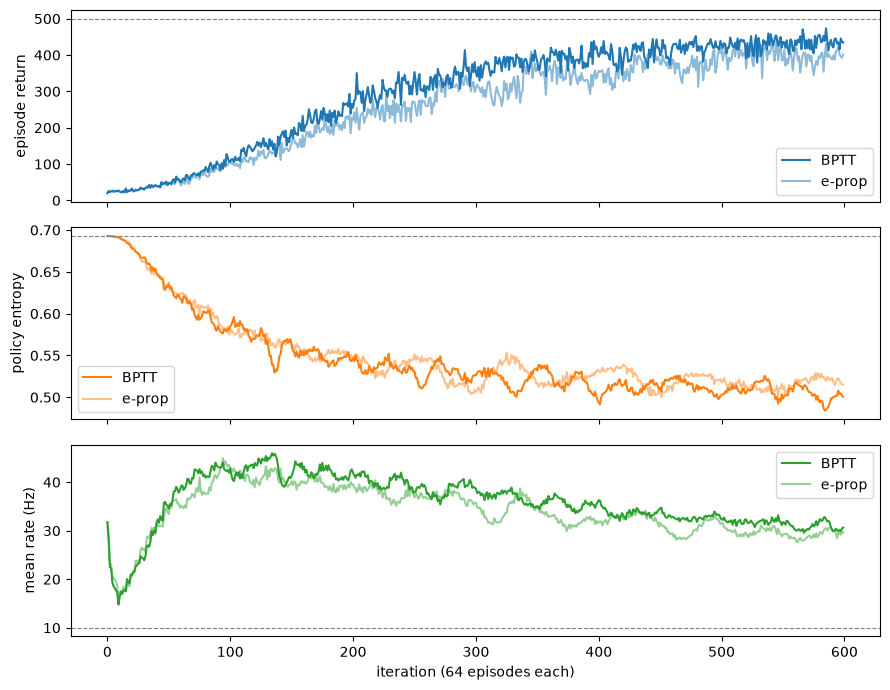

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for alpha, (name, history) in zip([1.0, 0.5], histories.items()):
    it = history["iteration"].astype(int)
    axes[0].plot(it, history["episode_return"], color='C0', alpha=alpha, label=name)
    axes[1].plot(it, history["entropy"], color='C1', alpha=alpha, label=name)
    axes[2].plot(it, history["rate"], color='C2', alpha=alpha, label=name)

axes[0].axhline(500, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("episode return")
axes[1].axhline(np.log(2), color="gray", ls="--", lw=0.8)
axes[1].set_ylabel("policy entropy")
axes[2].axhline(10, color="gray", ls="--", lw=0.8)
axes[2].set_ylabel("mean rate (Hz)")
axes[2].set_xlabel("iteration (64 episodes each)")
for ax in axes: ax.legend()
plt.tight_layout()

Test

In [8]:
for name, weights in [("BPTT", weights_bptt), ("e-prop", weights_eprop)]:
    for greedy in [False, True]:
        episodes = rollout_batch(test_key, 100, weights, params[name], env, env_params,
                                 encoder, greedy=greedy)
        returns = np.asarray(episodes.rewards.sum(axis=1))
        print(f"{name:6s} {'greedy ' if greedy else 'sampled'}: return {returns.mean():5.1f} ± "
              f"{returns.std() / np.sqrt(len(returns)):4.1f}, reaching 500: {np.mean(returns == 500):.0%}")

BPTT   sampled: return 437.5 ± 12.0, reaching 500: 69%
BPTT   greedy : return 500.0 ±  0.0, reaching 500: 100%
e-prop sampled: return 392.2 ± 14.4, reaching 500: 49%
e-prop greedy : return 496.6 ±  2.5, reaching 500: 98%


Example episode (e-prop)

Sampled actions, as in training.

From top: 
- pole angle and cart position
- input spikes, colored by the observation they encode (ON and OFF channels, background in gray)
- spikes of the recurrent network
- probability of pushing right (policy readout)
- value estimate (scaled back to returns) together with the return it is trained on

The rollout always runs 500 decision steps. If the episode ends earlier, the environment restarts and the network keeps running, but these steps (shaded) are masked out of the loss.

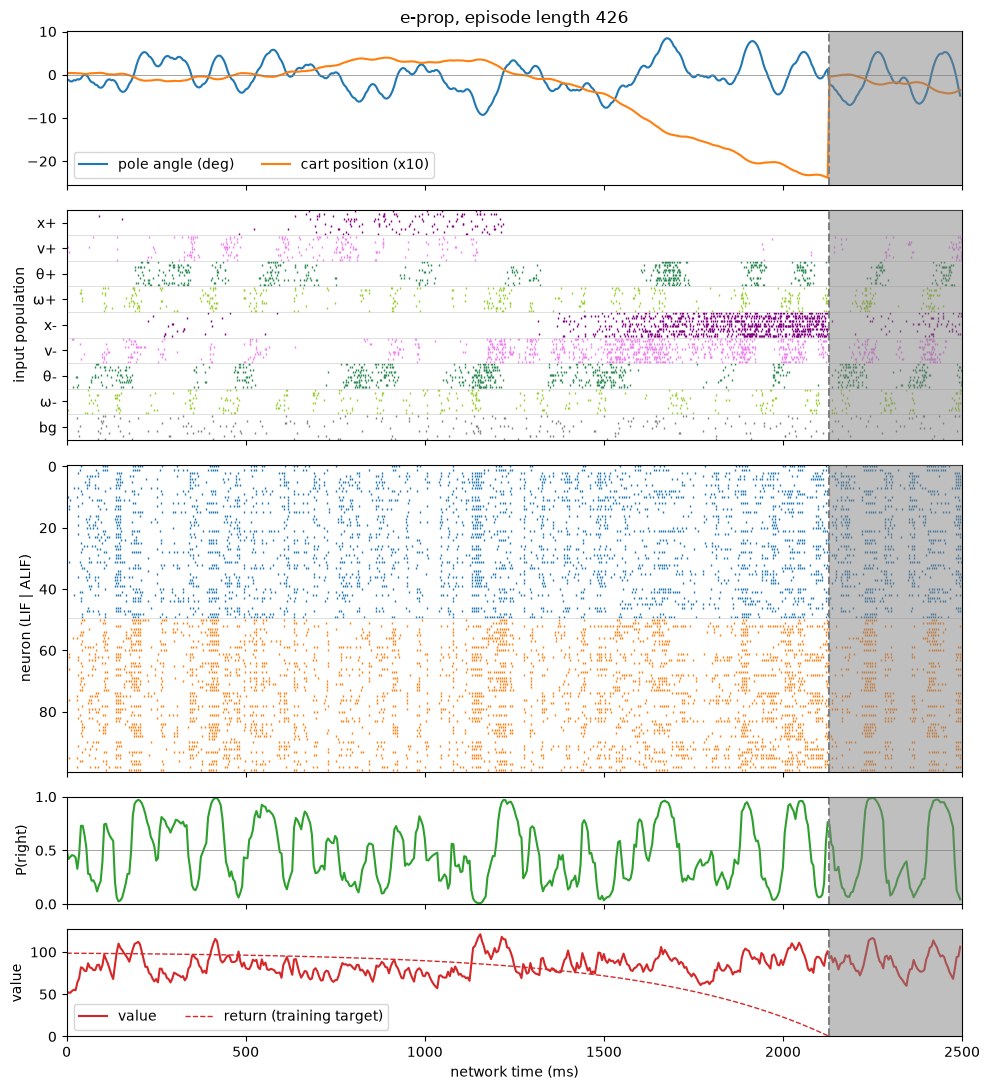

In [9]:
OBSERVATION_COLORS = ["purple", "violet", "seagreen", "yellowgreen"]
INPUT_LABELS = ["x+", "v+", "θ+", "ω+", "x-", "v-", "θ-", "ω-", "bg"]

ep = rollout(jax.random.key(7), weights_eprop, params["e-prop"], env, env_params, encoder)
n_steps = 5
max_steps = len(ep.valid)
length = int(ep.valid.sum())
t_decision = np.arange(max_steps) * n_steps # ms at the start of each decision
t_end = length * n_steps # ms at the end of the episode
t_max = max_steps * n_steps # ms at the end of the rollout
_, states, y = network.run(ep.x, weights_eprop, params["e-prop"])

logits, values_scaled = split_readout(y, n_steps)
p_right = np.asarray(jax.nn.softmax(logits, axis=-1)[:, 1])
values = np.asarray(values_scaled) / (1 - GAMMA)
returns = np.asarray(discounted_returns(ep.rewards, ep.truncated, values[-1], GAMMA))[:length]

fig, axes = plt.subplots(5, 1, figsize=(10, 11), sharex=True, gridspec_kw={"height_ratios": [1, 1.5, 2, 0.7, 0.7]})

# Environment
axes[0].plot(t_decision, np.degrees(np.asarray(ep.obs[:, 2])), label="pole angle (deg)")
axes[0].plot(t_decision, np.asarray(ep.obs[:, 0]) * 10, label="cart position (x10)")
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].legend(loc="lower left", ncol=2)
axes[0].set_title(f"e-prop, episode length {length}")

# Input spikes
n_obs, n_population = len(OBSERVATION_COLORS), encoder.n_population
input_times, input_ids = np.nonzero(np.asarray(ep.x))
population = input_ids // n_population
for k in range(len(INPUT_LABELS)):
    color = "gray" if k == 2 * n_obs else OBSERVATION_COLORS[k % n_obs]
    is_k = population == k
    axes[1].plot(input_times[is_k], input_ids[is_k], "|", color=color, ms=1.5)
for k in range(1, len(INPUT_LABELS)):
    axes[1].axhline(k * n_population - 0.5, color="lightgray", lw=0.5)
axes[1].set_yticks([(k + 0.5) * n_population - 0.5 for k in range(len(INPUT_LABELS))], INPUT_LABELS)
axes[1].set_ylim(encoder.n_in - 0.5, -0.5)
axes[1].set_ylabel("input population")

# Recurrent spikes
spike_times, neurons = np.nonzero(np.asarray(states.neuron.z))
is_alif = np.asarray(params["e-prop"].neuron.is_alif)[neurons]
axes[2].plot(spike_times[~is_alif], neurons[~is_alif], "|", color="C0", ms=1.5)
axes[2].plot(spike_times[is_alif], neurons[is_alif], "|", color="C1", ms=1.5)
axes[2].axhline(N_LIF - 0.5, color="lightgray", lw=0.5)
axes[2].set_ylim(N_LIF + N_ALIF - 0.5, -0.5)
axes[2].set_ylabel("neuron (LIF | ALIF)")

# Policy readout
axes[3].plot(t_decision, p_right, color="C2")
axes[3].axhline(0.5, color="gray", lw=0.5)
axes[3].set_ylim(0, 1)
axes[3].set_ylabel("P(right)")

# Value readout
axes[4].plot(t_decision, values, color="C3", label="value")
axes[4].plot(t_decision[:length], returns, color="C3", ls="--", lw=1, label="return (training target)")
axes[4].set_ylim(bottom=0)
axes[4].set_ylabel("value")
axes[4].legend(loc="lower left", ncol=2)
axes[4].set_xlabel("network time (ms)")
axes[4].set_xlim(0, t_max)

# Steps after the end of the episode:
# the rollout continues, but they are masked out of the loss
if length < max_steps:
    for ax in axes:
        ax.axvline(t_end, color="gray", ls="--")
        ax.axvspan(t_end, t_max, color="gray", alpha=0.5, lw=0, zorder=10)

plt.tight_layout()